# Verificación estadística de características
**Trabajo Final IA I · 22/10/2026**

Antes de PCA y clusterización, revisamos si una misma característica cambia poco entre
muestras de una clase y si cambia más entre clases. Cada **columna** conserva su significado:
no promediamos los 144 ni los 160 componentes entre sí.

- Huellas: clase = identidad; análisis principal solo con entrenamiento autorizado.
- Audio: clase = palabra, independientemente de la voz. Los seis hablantes actuales se
  destinan a entrenamiento y diagnóstico mediante `config/particiones_audio_v1.json`.
  El catálogo original sigue conservado. No hay prueba independiente de audio actual.
- H001/H002 participaron en desarrollo; H006 ya estaba previsto para entrenamiento.
  El resto del corte actual se usa también para desarrollo, sin afirmar independencia.
- Las voces nuevas podrán pronunciar comandos en vivo sin estar en entrenamiento;
  que funcione bien deberá comprobarse después con voces reservadas.

Vectorizar transforma cada muestra con reglas fijas. Entrenar utilizará después sus
vectores y etiquetas para K-NN. Este notebook no entrena ni ajusta escaladores o PCA.

Antes de ejecutar, desde la raíz, en PowerShell:
```powershell
.\.venv\Scripts\python.exe src/extraer_dataset_huellas.py
.\.venv\Scripts\python.exe src/extraer_dataset_audio.py
```
Si ya existen extracciones compatibles no hace falta regenerarlas. Seleccionar `.venv`
como kernel y ejecutar todas las celdas. Solo se requieren las dependencias existentes.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/conjunto_v1.json").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrí el notebook dentro del repositorio.")
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from verificacion_estadistica import (
    cargar_ejecucion, aplicar_mapa_audio, leer_json, guardar_json, guardar_csv,
    cantidades, analizar, sha,
)

# Opcionales: rutas relativas exactas de extracciones compatibles, no de NPZ sueltos.
EJECUCION_HUELLAS = ""
EJECUCION_AUDIO = ""
CORTE = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
SALIDA = RAIZ / "resultados/verificacion_estadistica" / CORTE
SALIDA.mkdir(parents=True, exist_ok=False)
print("Salida nueva:", SALIDA.relative_to(RAIZ))


Salida nueva: resultados\verificacion_estadistica\20261022T141121_625126Z


## Cálculos por clase y por característica
Para una clase $c$ con $n_c$ muestras y una columna $j$:
$$\boxed{\bar x_{cj}=\frac{1}{n_c}\sum_{i\in c}x_{ij}},\qquad
\boxed{s_{cj}=\sqrt{\frac{\sum_{i\in c}(x_{ij}-\bar x_{cj})^2}{n_c-1}}}.$$

Usamos desviación **muestral**, `ddof=1`. Con una sola muestra hay media pero la
DE queda vacía, con estado `n_menor_2`. Una clase sin muestras no tiene estadísticas;
se detecta en el catálogo de uso y sus cantidades. No se interpreta su ausencia como DE cero.
La DE de una columna MFCC entre grabaciones es distinta de las DE que el extractor
ya calculó entre ventanas dentro de una grabación (`ddof=0`).

Para ordenar usamos un único indicador, razón de dispersión entre clases e interna:
$$\boxed{S_j=\frac{\sum_c n_c(\bar x_{cj}-\bar x_j)^2}
{\sum_c\sum_{i\in c}(x_{ij}-\bar x_{cj})^2}}.$$

Cuanto mayor, más separación de medias respecto de variación interna. Es invariante
a cambiar la escala lineal de esa columna; no comparamos sus medias o DE brutas con
las de otra columna. No es un test ANOVA ni un p-valor y no tiene umbral universal.
Si toda la columna es constante, $0/0$ queda indefinido. Si solo la dispersión interna
es cero, el indicador es infinito (estado explícito y celda numérica vacía). Si faltan
clases o no quedan grados de libertad internos, queda `insuficiente`.

Los no finitos se exportan y detienen el análisis sin eliminar muestras. Las constantes
globales y por clase se informan y se conservan. Las cantidades provienen de los catálogos.


Extracción: datos\caracteristicas\huellas\glcm_opuestas_v1_89a0f3928fb3\ejecucion_20261022T140926_860560Z
Entrenamiento autorizado: [{'identidad': 'A01', 'n': 40}, {'identidad': 'A02', 'n': 40}, {'identidad': 'A03', 'n': 40}]
{
  "muestras": 120,
  "caracteristicas": 144,
  "cantidades": {
    "A01": 40,
    "A02": 40,
    "A03": 40
  },
  "no_finitos": 0,
  "constantes_globales": 0
}


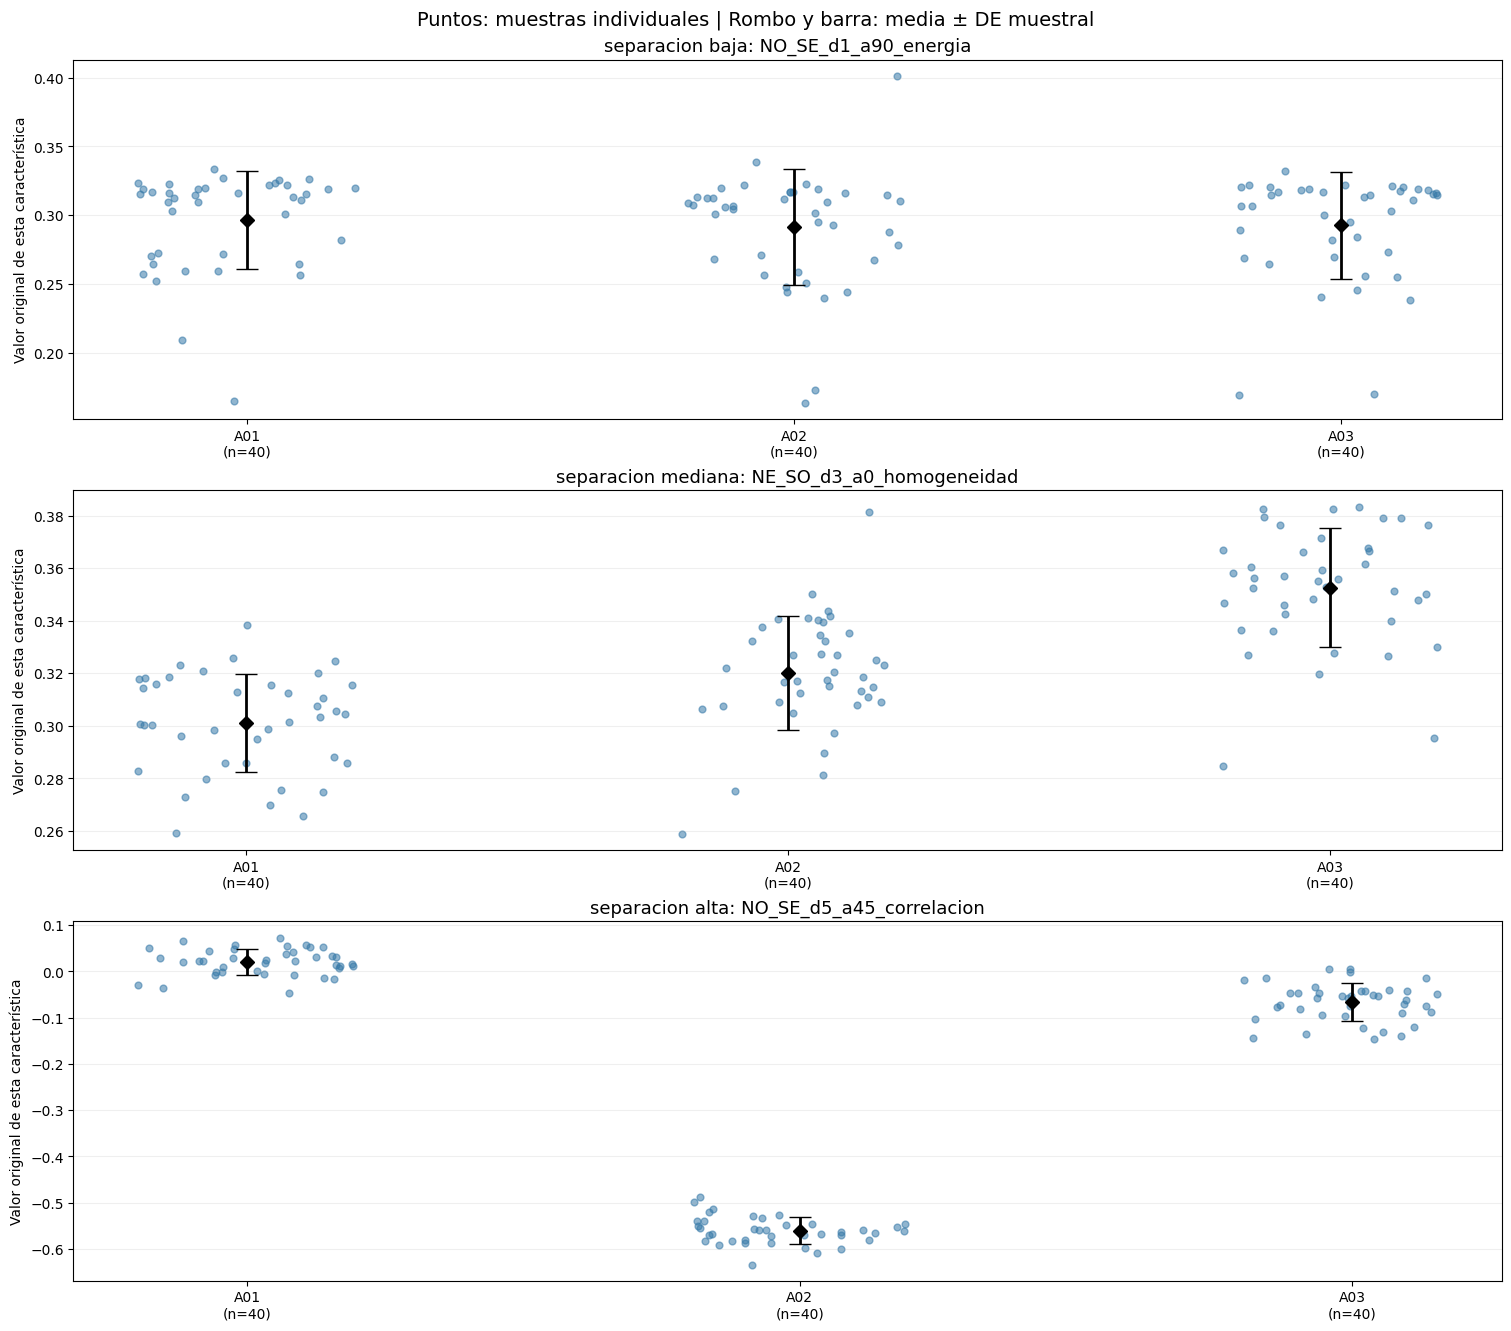

In [2]:
huellas = cargar_ejecucion(RAIZ, "huellas", EJECUCION_HUELLAS)
cat_h = huellas["catalogo"]
uso_h = [dict(r, usar_analisis=str(r["particion"] == "entrenamiento"
                                 and r["grupo"] == "autorizado")) for r in cat_h]
guardar_csv(SALIDA / "catalogo_uso_huellas.csv", uso_h)
guardar_csv(SALIDA / "cantidades_catalogo_huellas.csv",
            cantidades(cat_h, ["particion", "grupo", "identidad", "estado_extraccion"]))
problemas = [r["muestra"] for r in uso_h
             if r["usar_analisis"] == "True" and r["estado_extraccion"] != "vectorizada"]
if problemas:
    raise ValueError(f"Entrenamiento autorizado sin vector: {problemas}. Revisar catálogo de uso.")
mask_h = np.array([r["particion"] == "entrenamiento" and r["grupo"] == "autorizado"
                   for r in huellas["filas"]])
filas_h = [r for r, usar in zip(huellas["filas"], mask_h) if usar]
y_h = np.array([r["identidad"] for r in filas_h])
conteo_h = cantidades(filas_h, ["identidad"])
guardar_csv(SALIDA / "cantidades_usadas_huellas.csv", conteo_h)
print("Extracción:", huellas["carpeta"].relative_to(RAIZ))
print("Entrenamiento autorizado:", conteo_h)
res_h = analizar(SALIDA / "huellas", huellas["X"][mask_h], huellas["ids"][mask_h],
                 huellas["nombres"], y_h)
print(json.dumps(res_h["resumen"], ensure_ascii=False, indent=2))
plt.show()


Los intrusos no participan del análisis principal y no se agrupan como una identidad
ficticia. Tampoco se analizan aquí las muestras de validación ni las de prueba.
Las ampliaciones de una base sintética comparten procedencia: no equivalen a muestras
independientes de muchos dedos reales.

Se muestran **tres columnas no constantes**: menor, mediana y mayor separación,
con desempate alfabético. Los casos indefinidos no se ordenan; quedan en las tablas.
Una separación infinita aparece al final del orden. No hay selección automática de variables.
Cada panel conserva su escala propia y muestra todas las muestras utilizadas.
**Media ± DE no es un intervalo de confianza ni contiene necesariamente todos los datos.**


In [3]:
print("Características mostradas en huellas:")
for r in res_h["elegidas"]:
    print(r["criterio"], r["caracteristica"], r["separacion"], r["estado"])
    for fila in res_h["tabla"]:
        if fila["caracteristica"] == r["caracteristica"]:
            print("  ", fila)


Características mostradas en huellas:
separacion_baja NO_SE_d1_a90_energia 0.003402814053670197 ok
   {'clase': 'A01', 'caracteristica': 'NO_SE_d1_a90_energia', 'descripcion': 'NO+SE, distancia nominal 1 px, ángulo 90 energia', 'n': 40, 'media': 0.2964901941130092, 'desviacion_muestral': 0.03595304384288944, 'estado': 'ok'}
   {'clase': 'A02', 'caracteristica': 'NO_SE_d1_a90_energia', 'descripcion': 'NO+SE, distancia nominal 1 px, ángulo 90 energia', 'n': 40, 'media': 0.29119927032552007, 'desviacion_muestral': 0.042326075639819646, 'estado': 'ok'}
   {'clase': 'A03', 'caracteristica': 'NO_SE_d1_a90_energia', 'descripcion': 'NO+SE, distancia nominal 1 px, ángulo 90 energia', 'n': 40, 'media': 0.29251382388668473, 'desviacion_muestral': 0.03860857533285563, 'estado': 'ok'}
separacion_mediana NE_SO_d3_a0_homogeneidad 1.041667531815432 ok
   {'clase': 'A01', 'caracteristica': 'NE_SO_d3_a0_homogeneidad', 'descripcion': 'NE+SO, distancia nominal 3 px, ángulo 0 homogeneidad', 'n': 40, 'media

## Audio: palabras y hablantes
El mapa se aplica como una capa explícita `particion_analisis`, sin reescribir catálogos
ni invalidar extracciones. Una asignación previa incompatible o un hablante nuevo
**detiene** el uso: hay que decidir su partición. Nuevas muestras de un hablante ya
asignado heredan su partición explícita; no se hace un sorteo por archivo.

El análisis utiliza únicamente entrenamiento con decisión humana `conservar`.
Las exclusiones y los avisos permanecen en los catálogos exportados. No se cambian
las revisiones auditivas. Si se agregan futuras voces de validación/prueba al mapa,
no entrarán en este diagnóstico de entrenamiento.


Extracción: datos\caracteristicas\audio\audio_segmentos_v1_1caab0e82325\ejecucion_20261022T140942_486999Z
Usadas por comando: [{'comando': 'identificar', 'n': 60}, {'comando': 'reconocer', 'n': 60}, {'comando': 'salir', 'n': 59}]
Por hablante y comando: [{'hablante': 'H001', 'comando': 'identificar', 'n': 10}, {'hablante': 'H001', 'comando': 'reconocer', 'n': 10}, {'hablante': 'H001', 'comando': 'salir', 'n': 10}, {'hablante': 'H002', 'comando': 'identificar', 'n': 10}, {'hablante': 'H002', 'comando': 'reconocer', 'n': 10}, {'hablante': 'H002', 'comando': 'salir', 'n': 10}, {'hablante': 'H003', 'comando': 'identificar', 'n': 10}, {'hablante': 'H003', 'comando': 'reconocer', 'n': 10}, {'hablante': 'H003', 'comando': 'salir', 'n': 10}, {'hablante': 'H004', 'comando': 'identificar', 'n': 10}, {'hablante': 'H004', 'comando': 'reconocer', 'n': 10}, {'hablante': 'H004', 'comando': 'salir', 'n': 10}, {'hablante': 'H005', 'comando': 'identificar', 'n': 10}, {'hablante': 'H005', 'comando': 'rec

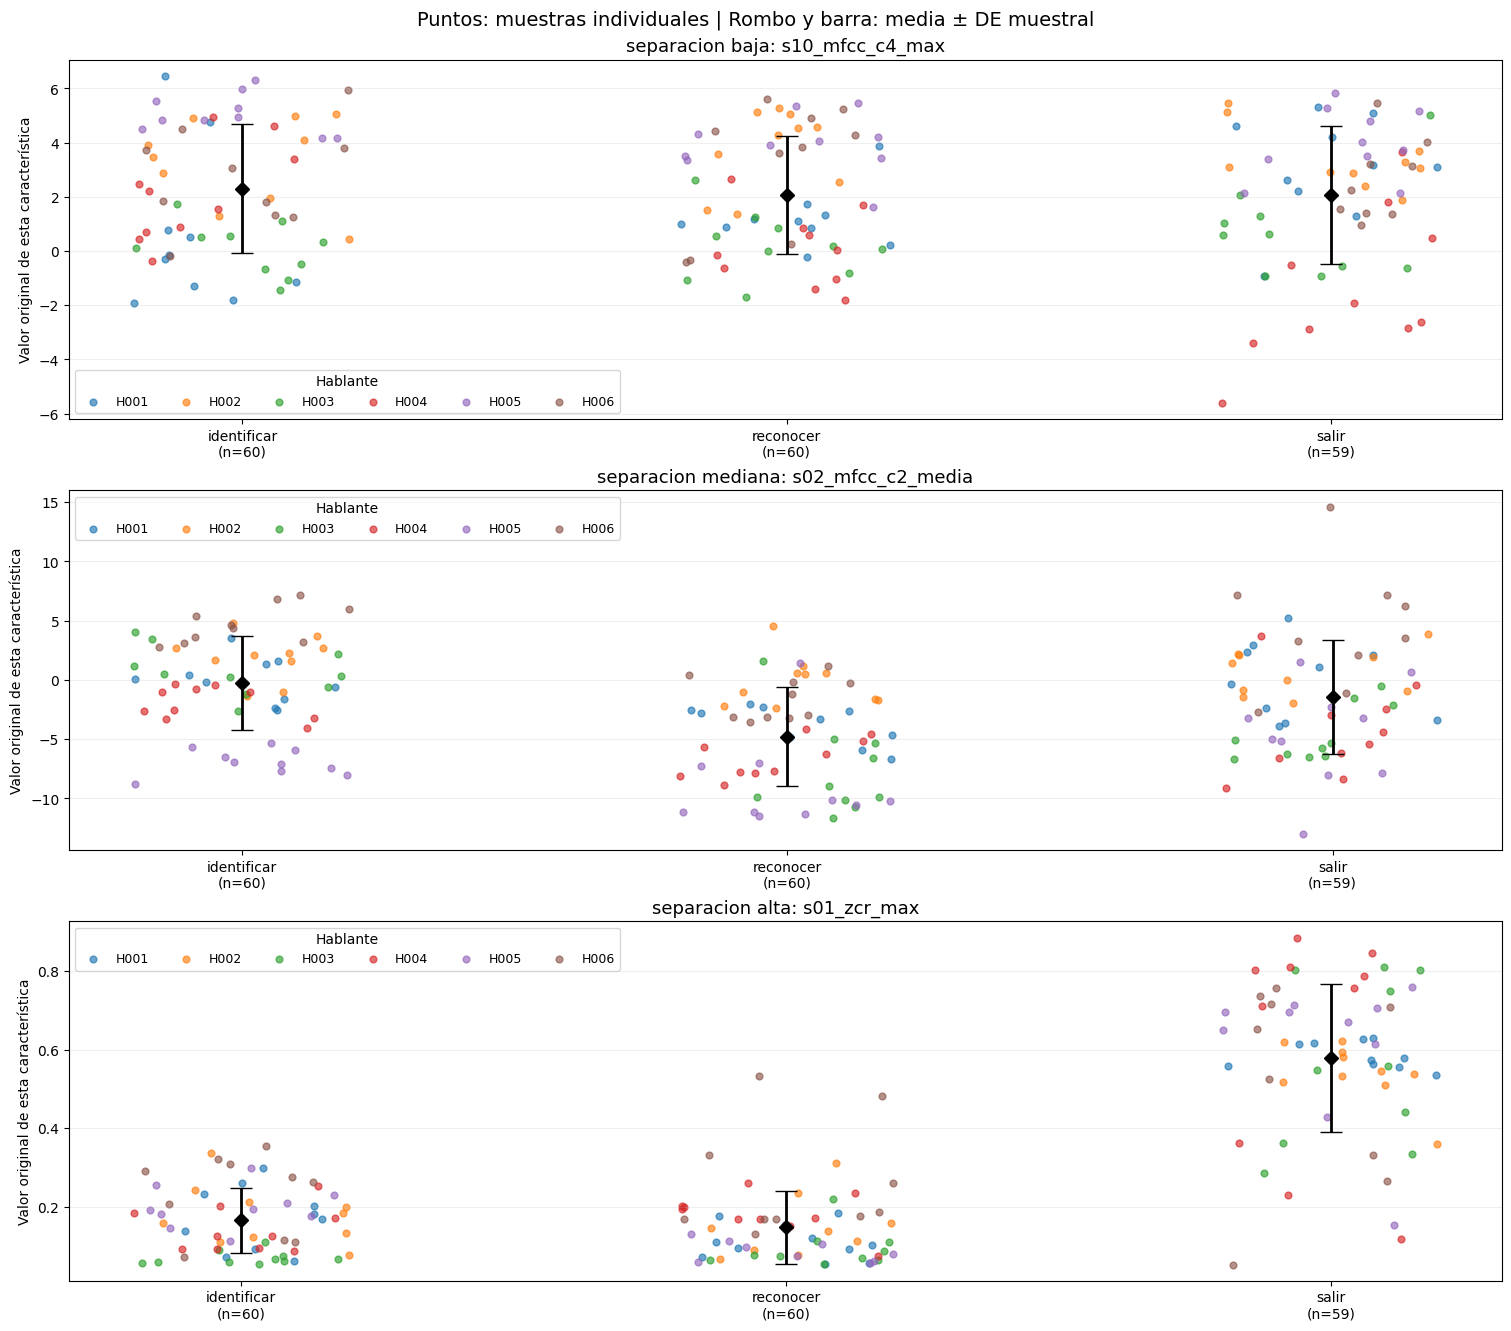

In [4]:
audio = cargar_ejecucion(RAIZ, "audio", EJECUCION_AUDIO)
RUTA_MAPA = RAIZ / "config/particiones_audio_v1.json"
mapa = leer_json(RUTA_MAPA)
cat_a = aplicar_mapa_audio(audio["catalogo"], mapa)
filas_a_todas = aplicar_mapa_audio(audio["filas"], mapa)
uso_a = [dict(r, usar_analisis=str(r["particion_analisis"] == "entrenamiento"
                                 and r["decision_revision"] == "conservar")) for r in cat_a]
guardar_csv(SALIDA / "catalogo_uso_audio.csv", uso_a)
guardar_json(SALIDA / "particiones_audio_aplicadas.json", mapa)
guardar_csv(SALIDA / "cantidades_catalogo_audio.csv", cantidades(cat_a,
            ["particion_analisis", "hablante", "comando", "decision_revision", "estado_extraccion"]))
problemas = [r["muestra_id"] for r in cat_a
             if r["particion_analisis"] == "entrenamiento"
             and r["decision_revision"] != "excluir"
             and (r["decision_revision"] != "conservar" or r["estado_extraccion"] != "vectorizada")]
if problemas:
    raise ValueError(f"Audios de entrenamiento pendientes o sin vector: {problemas}. Revisar sin descartarlos.")
mask_a = np.array([r["particion_analisis"] == "entrenamiento"
                   and r["decision_revision"] == "conservar" for r in filas_a_todas])
filas_a = [r for r, usar in zip(filas_a_todas, mask_a) if usar]
y_a = np.array([r["comando"] for r in filas_a])
hablantes = np.array([r["hablante"] for r in filas_a])
guardar_csv(SALIDA / "cantidades_usadas_audio.csv", cantidades(filas_a, ["comando"]))
guardar_csv(SALIDA / "cantidades_hablante_comando.csv", cantidades(filas_a, ["hablante", "comando"]))
print("Extracción:", audio["carpeta"].relative_to(RAIZ))
print("Usadas por comando:", cantidades(filas_a, ["comando"]))
print("Por hablante y comando:", cantidades(filas_a, ["hablante", "comando"]))
res_a = analizar(SALIDA / "audio", audio["X"][mask_a], audio["ids"][mask_a],
                 audio["nombres"], y_a, hablantes)
print(json.dumps(res_a["resumen"], ensure_ascii=False, indent=2))
plt.show()


Los colores identifican voces, pero **la voz no entra en el vector numérico**.
Se aplica el mismo criterio de columnas baja/mediana/alta a los comandos.

La revisión complementaria calcula el mismo indicador de dos maneras:
- Separación de palabras dentro de cada hablante: ¿las palabras cambian en una misma voz?
- Separación de hablantes dentro de cada palabra: ¿cambia mucho una palabra entre voces?

Las tablas condicionales incluyen medias y DE para todas las combinaciones observadas.
Las cantidades permiten detectar combinaciones ausentes. Una separación alta entre voces
puede señalar sensibilidad al hablante. Se contrasta con la separación entre palabras,
los puntos y las medias, sin declarar una dominancia universal por comparar cifras con
distinta cantidad de grupos. Las repeticiones de una persona no son voces independientes;
no se calculan pruebas de significación ni intervalos de confianza aquí.


In [5]:
from verificacion_estadistica import separacion
print("Características mostradas en audio:")
condicionales = []
for analisis, estratos, grupos in [("palabra dentro hablante", hablantes, y_a),
                                   ("hablante dentro palabra", y_a, hablantes)]:
    for estrato in sorted(set(estratos)):
        mask = estratos == estrato
        condicionales.extend(dict(analisis=analisis, estrato=str(estrato), **r)
            for r in separacion(audio["X"][mask_a][mask], grupos[mask], audio["nombres"]))
for r in res_a["elegidas"]:
    print("\n", r["criterio"], r["caracteristica"], r["separacion"], r["estado"])
    for fila in res_a["tabla"]:
        if fila["caracteristica"] == r["caracteristica"]:
            print("  ", fila)
    for fila in condicionales:
        if fila["caracteristica"] == r["caracteristica"]:
            print("  ", fila["analisis"], fila["estrato"], fila["separacion"], fila["estado"])


Características mostradas en audio:

 separacion_baja s10_mfcc_c4_max 0.002430652761214895 ok
   {'clase': 'identificar', 'caracteristica': 's10_mfcc_c4_max', 'descripcion': 'Segmento 10: mfcc c4 max', 'n': 60, 'media': 2.306132935609539, 'desviacion_muestral': 2.3806889070962027, 'estado': 'ok'}
   {'clase': 'reconocer', 'caracteristica': 's10_mfcc_c4_max', 'descripcion': 'Segmento 10: mfcc c4 max', 'n': 60, 'media': 2.0556790261954325, 'desviacion_muestral': 2.177784451053043, 'estado': 'ok'}
   {'clase': 'salir', 'caracteristica': 's10_mfcc_c4_max', 'descripcion': 'Segmento 10: mfcc c4 max', 'n': 59, 'media': 2.065534347101753, 'desviacion_muestral': 2.548105558169674, 'estado': 'ok'}
   palabra dentro hablante H001 0.28896399675852225 ok
   palabra dentro hablante H002 0.02364675859737428 ok
   palabra dentro hablante H003 0.05106936896249312 ok
   palabra dentro hablante H004 0.5272830222257123 ok
   palabra dentro hablante H005 0.26903710051732593 ok
   palabra dentro hablante H0

## Registro y conclusiones de la ejecución
La celda siguiente guarda rutas, hashes de entradas, configuraciones efectivas,
versiones y muestras usadas. Cada ejecución escribe una carpeta nueva.

Para interpretar: una columna con medias distantes respecto de sus DE es prometedora.
Si se mezclan puntos de clases distintas, esa columna por sí sola no las distingue bien.
Eso no obliga a eliminarla: podría aportar información al combinarla con otras.
Los casos extremos son ejemplos diagnósticos; no resumen el descriptor completo.

**Completar después de ejecutar en Windows:** comparar las tres columnas y revisar la
tabla por hablante. Una separación favorable en entrenamiento no demuestra precisión
ni garantiza reconocimiento en vivo. Reservar personas nuevas para validación (ajustes)
y otras para prueba final, sin emplear esta última para elegir parámetros.
La demostración con el profesor, la profesora o el autor debe etiquetarse según su uso
previo: una voz conocida puede ser demostración válida, pero no prueba de voz desconocida.


In [6]:
registro = {
    "fecha_utc": CORTE, "entorno": {p: importlib.metadata.version(p)
        for p in ("numpy", "scipy", "Pillow", "matplotlib")},
    "ddof_tablas": 1, "prueba_analizada": False,
    "modelos_ajustados": False, "audio_prueba_independiente_disponible": False,
    "mapa_audio_sha256": sha(RUTA_MAPA),
    "codigo_analisis_sha256": sha(RAIZ / "src/verificacion_estadistica.py"),
}
for modalidad, datos, resultado, filas, campo_id in [
    ("huellas", huellas, res_h, filas_h, "muestra"),
    ("audio", audio, res_a, filas_a, "muestra_id")]:
    registro[modalidad] = dict(
        extraccion=datos["carpeta"].relative_to(RAIZ).as_posix(),
        manifiesto_sha256=sha(datos["carpeta"] / "manifiesto.json"),
        configuracion=leer_json(datos["carpeta"] / "config_efectiva.json"),
        muestras_usadas=[r[campo_id] for r in filas],
        resumen=resultado["resumen"], ejemplos=resultado["elegidas"],
        advertencia="Diagnóstico de entrenamiento; no mide precisión.",
    )
guardar_json(SALIDA / "resumen.json", registro)
# Copia del módulo exacto utilizado para documentar esta ejecución.
import shutil
shutil.copyfile(RAIZ / "src/verificacion_estadistica.py", SALIDA / "fuente_verificacion_estadistica.py")
print("Tablas, gráficos y registro:", SALIDA.relative_to(RAIZ))
print("Compartir resumen.json, ambos distribuciones.png y audio/separacion_condicional.csv.")


Tablas, gráficos y registro: resultados\verificacion_estadistica\20261022T141121_625126Z
Compartir resumen.json, ambos distribuciones.png y audio/separacion_condicional.csv.
